# Step 12 — Lid-Driven Cavity Flow

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step12_cavity_flow.ipynb)

*Part of [Steps to Navier–Stokes](../guide/steps_to_navier_stokes.md), after Lorena Barba's CFD Python; moved from somax's tutorial series.*

The [lid-driven cavity](https://en.wikipedia.org/wiki/Lid_driven_cavity_problem) is the canonical benchmark for 2D incompressible Navier–Stokes solvers. A square box has no-slip walls on all four sides, with the top lid sliding at constant velocity $u_\text{lid} = 1$.

**What you'll learn:**

1. How to set up and integrate a Navier–Stokes model in sesmax
2. How to recover velocity and streamfunction with `model.diagnose()`
3. How to compare against the Ghia benchmark

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

In the vorticity–streamfunction formulation the vorticity is advected and diffused,

$$
\frac{\partial \omega}{\partial t} + u \frac{\partial \omega}{\partial x} + v \frac{\partial \omega}{\partial y} = \nu \nabla^2 \omega
$$

and the streamfunction, and through it the velocity, follows from a Poisson equation:

$$
\nabla^2 \psi = -\omega
$$

$$
u = \frac{\partial \psi}{\partial y}
$$

$$
v = -\frac{\partial \psi}{\partial x}
$$

At each time step we:

1. Invert the Poisson equation $\nabla^2 \psi = -\omega$ to get the streamfunction (the [Step 10](step10_poisson_2d.ipynb) solver)
2. Compute velocity from $\psi$
3. Advect and diffuse $\omega$
4. Apply the wall boundary conditions (Thom's formula for wall vorticity)

The Reynolds number is $\mathrm{Re} = u_\text{lid} L_x / \nu$. At $\mathrm{Re} = 100$ the flow is steady and well characterised by the benchmark data of Ghia et al. (1982).

### Symbols

Everything is nondimensional, and $(x, y)$ are the spatial coordinates.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $(x, y) \in [0, L_x] \times [0, L_y]$ | spatial coordinates | $\mathbb{R}^2$ |
| $t$ | time | $\mathbb{R}$ |
| $\omega(x, y, t)$ | vorticity | $\mathbb{R}$ |
| $\psi(x, y, t)$ | streamfunction | $\mathbb{R}$ |
| $u(x, y, t)$, $v(x, y, t)$ | velocity components | $\mathbb{R}$ |
| $\nu$ | viscosity, the model's differentiable parameter | $\mathbb{R}_{>0}$ |
| $u_\text{lid}$, $\mathrm{Re}$ | lid speed and Reynolds number | $\mathbb{R}$, $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior cells along $x$ and $y$ | count |
| $\Delta x$, $\Delta y$, $\Delta n$, $\Delta t$ | grid spacings, spacing normal to a wall, time step | $\mathbb{R}_{>0}$ |
| $\mathcal{E}$ | enstrophy | $\mathbb{R}_{\ge 0}$ |

## Grid layout and boundary conditions

The vorticity $\omega$ and streamfunction $\psi$ live on the grid's nodes, and the walls are nodes $0$ and $N_{\Omega_x,x}$ (or $N_{\Omega_x,y}$); the last row and column of each array are ghosts.

| Wall | $u$ | $v$ |
| --- | --- | --- |
| Top (the moving lid) | $u_\text{lid} = 1$ | $0$ |
| Bottom | $0$ | $0$ |
| Left and right | $0$ | $0$ |

At walls, vorticity is computed from **Thom's formula**:

$$
\omega_\text{wall} = -\frac{2 (\psi_\text{interior} - \psi_\text{wall})}{\Delta n^2}
$$

At the top lid, moving at $u_\text{lid}$, an extra term accounts for the wall velocity:

$$
\omega_\text{top} = -\frac{2 \psi_\text{interior}}{\Delta y^2} - \frac{2 u_\text{lid}}{\Delta y}
$$

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt
from sesmax_core._src.testing.pde2d.navier_stokes import (
    GHIA_RE100_U,
    GHIA_RE100_V,
    GHIA_RE100_X,
    GHIA_RE100_Y,
)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

We use a $32 \times 32$ grid with $\nu = 0.01$, so $\mathrm{Re} = 100$.

In [4]:
# Shapes: N_Ωx,x = N_Ωx,y = 32 interior cells

num_cells_x = 32
num_cells_y = 32
viscosity = 0.01
lid_speed = 1.0

# today (sesmax_core)
model = sxt.IncompressibleNS2D.create(
    nx=num_cells_x,
    ny=num_cells_y,
    Lx=1.0,
    Ly=1.0,
    nu=viscosity,
    problem="cavity",
    u_lid=lid_speed,
)
# Re = u_lid L_x / ν
reynolds_number = lid_speed * model.grid.Lx / viscosity  # → ()

print(f"Grid: {model.grid.Ny} x {model.grid.Nx} (including ghost cells)")
print(f"dx = {model.grid.dx:.4f}, dy = {model.grid.dy:.4f}")
print(f"Re = {reynolds_number:.0f}")

Grid: 34 x 34 (including ghost cells)
dx = 0.0312, dy = 0.0312
Re = 100


## 2. Initial condition and integration

Start from rest, $\omega = 0$ everywhere, and integrate until the flow reaches a steady state. At $\mathrm{Re} = 100$ the flow converges within $t \approx 5$ to $10$, so we run to $t = 10$.

We use the default `Tsit5()` solver with a small time step for the stability of the explicit advection; 5,000 steps exceed diffrax's default `max_steps` of 4,096, so we raise it.

In [5]:
# Shapes: G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# ω(x, y, 0) = 0
rest_omega = jnp.zeros((model.grid.Ny, model.grid.Nx))  # → G
# today (sesmax_core)
rest_state = sxt.NSVorticityState(omega=rest_omega)

# today (sesmax_core, diffrax)
solution = model.integrate(  # ω → 1 × G
    rest_state,
    t0=0.0,
    t1=10.0,
    dt=0.002,
    saveat=dfx.SaveAt(t1=True),
    max_steps=10_000,
)

# The solver applies the wall vorticity inside each right-hand side evaluation;
# apply it once more so the saved field shows it too.
# today (sesmax_core)
final_state = sxt.NSVorticityState(omega=solution.ys.omega[0])
final_state = model.apply_boundary_conditions(final_state)
final_omega = final_state.omega  # → G

smallest = float(jnp.min(final_omega))
largest = float(jnp.max(final_omega))
print(f"Final omega range: [{smallest:.4f}, {largest:.4f}]")
print(f"All finite: {bool(jnp.all(jnp.isfinite(final_omega)))}")

Final omega range: [-64.0000, 24.4049]
All finite: True


## 3. Diagnostics: velocity and streamfunction

`model.diagnose()` recovers the streamfunction $\psi$ and velocity components $(u, v)$ from the vorticity field, along with the kinetic energy and enstrophy.

In [6]:
# today (sesmax_core)
diagnostics = model.diagnose(final_state)

print(f"Kinetic energy: {float(diagnostics.kinetic_energy):.6f}")
print(f"Enstrophy:      {float(diagnostics.enstrophy):.6f}")

Kinetic energy: 0.029581
Enstrophy:      10.171934


## 4. Visualise the flow

We plot the vorticity field, the streamfunction contours and the speed.

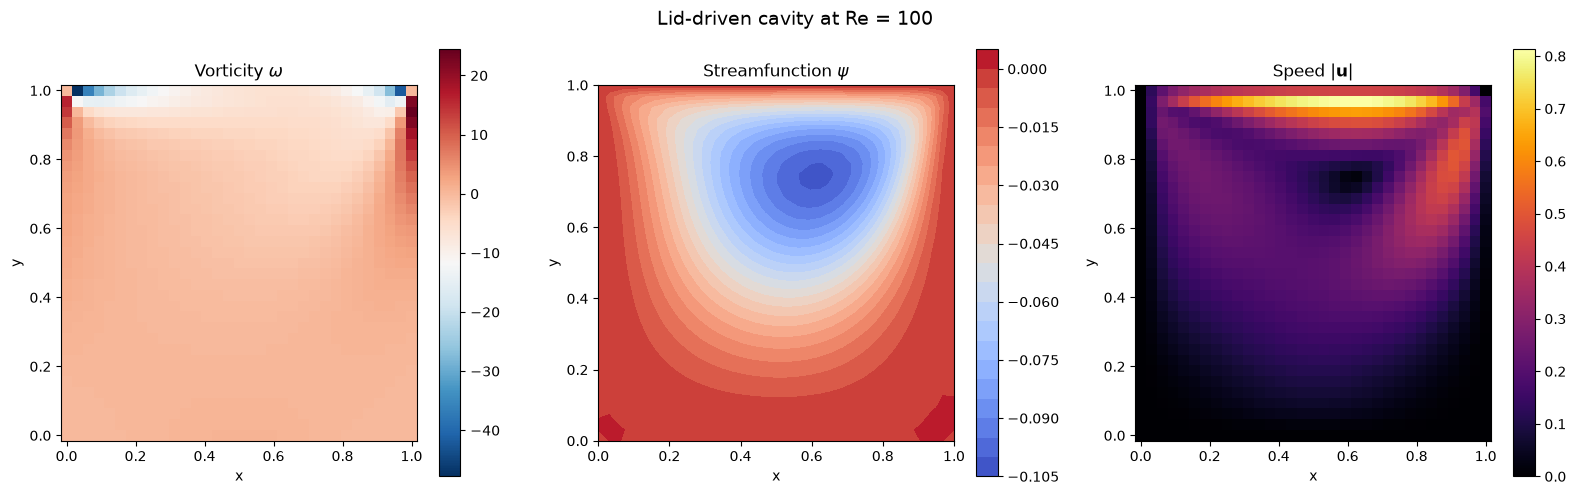

In [7]:
# Shapes: N_Ωx,x + 1 = 33 columns and N_Ωx,y + 1 = 33 rows of nodes, walls included;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# xᵢ = i Δx, for i = 0 … N_Ωx,x
x_position = jnp.arange(num_cells_x + 1) * model.grid.dx  # → (N_Ωx,x + 1,)
# yⱼ = j Δy, for j = 0 … N_Ωx,y
y_position = jnp.arange(num_cells_y + 1) * model.grid.dy  # → (N_Ωx,y + 1,)
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → (N_Ωx,y + 1) × (N_Ωx,x + 1)
nodes = (slice(0, num_cells_y + 1), slice(0, num_cells_x + 1))
# |u| = √(u² + v²)
speed = jnp.sqrt(diagnostics.u**2 + diagnostics.v**2)  # → G

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

pcm = axes[0].pcolormesh(
    x_grid, y_grid, final_omega[nodes], shading="auto", cmap="RdBu_r"
)
axes[0].set_title(r"Vorticity $\omega$")
plt.colorbar(pcm, ax=axes[0])

filled = axes[1].contourf(
    x_grid, y_grid, diagnostics.psi[nodes], levels=20, cmap="coolwarm"
)
axes[1].set_title(r"Streamfunction $\psi$")
plt.colorbar(filled, ax=axes[1])

pcm = axes[2].pcolormesh(x_grid, y_grid, speed[nodes], shading="auto", cmap="inferno")
axes[2].set_title(r"Speed $|\mathbf{u}|$")
plt.colorbar(pcm, ax=axes[2])

for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

plt.suptitle(f"Lid-driven cavity at Re = {reynolds_number:.0f}", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Ghia benchmark comparison

Ghia, Ghia & Shin (1982) tabulated centreline velocity profiles for the lid-driven cavity at various Reynolds numbers. The data for $\mathrm{Re} = 100$ is bundled in sesmax.

We extract $u$ along the vertical centreline ($x = 0.5$) and $v$ along the horizontal centreline ($y = 0.5$).

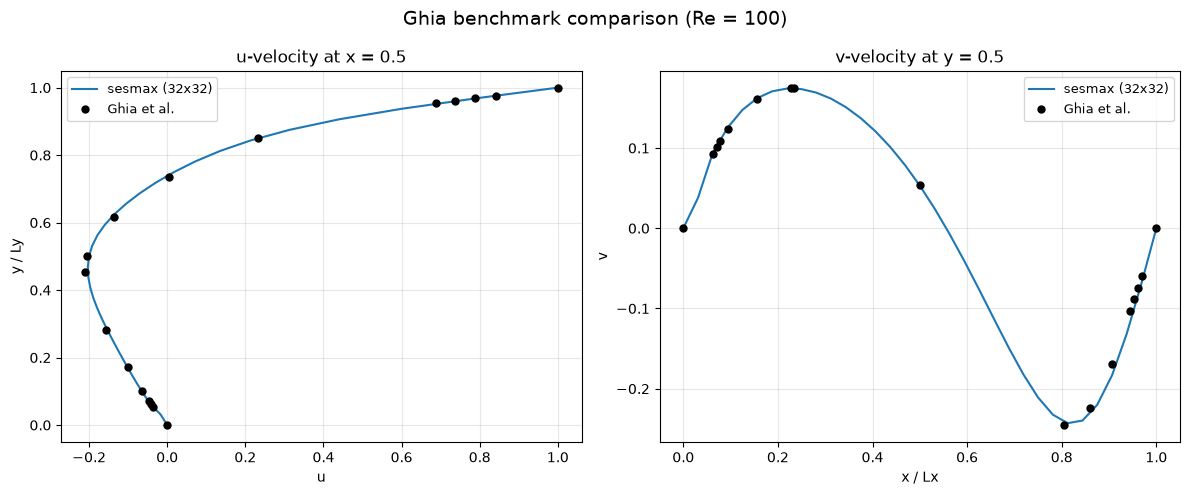

Max |u - u_Ghia| on x = 0.5: 0.0098
Max |v - v_Ghia| on y = 0.5: 0.0142


In [8]:
# Shapes: N_Ωx,y + 1 = 33 nodes on the vertical centreline, N_Ωx,x + 1 = 33 on the
# horizontal one

# x = 0.5 is node N_Ωx,x / 2, y = 0.5 is node N_Ωx,y / 2
middle_column = num_cells_x // 2
middle_row = num_cells_y // 2

# y / L_y, walls included
normalised_y = y_position / model.grid.Ly  # → (N_Ωx,y + 1,)
# x / L_x, walls included
normalised_x = x_position / model.grid.Lx  # → (N_Ωx,x + 1,)

# On the walls the velocity is set by the boundary conditions (no slip, and the
# lid speed on top); diagnose's centred difference there would read the ghost row.
# u(0.5, y), with u = 0 at the bottom and u = u_lid on the top
centre_u = diagnostics.u[: num_cells_y + 1, middle_column]  # → (N_Ωx,y + 1,)
centre_u = centre_u.at[0].set(0.0).at[-1].set(model.u_lid)  # → (N_Ωx,y + 1,)
# v(x, 0.5), with v = 0 on both side walls
centre_v = diagnostics.v[middle_row, : num_cells_x + 1]  # → (N_Ωx,x + 1,)
centre_v = centre_v.at[0].set(0.0).at[-1].set(0.0)  # → (N_Ωx,x + 1,)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
grid_label = f"sesmax ({num_cells_x}x{num_cells_y})"

ax = axes[0]
ax.plot(centre_u, normalised_y, "-", lw=1.5, label=grid_label)
ax.plot(GHIA_RE100_U, GHIA_RE100_Y, "ko", markersize=5, label="Ghia et al.")
ax.set_xlabel("u")
ax.set_ylabel("y / Ly")
ax.set_title("u-velocity at x = 0.5")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(normalised_x, centre_v, "-", lw=1.5, label=grid_label)
ax.plot(GHIA_RE100_X, GHIA_RE100_V, "ko", markersize=5, label="Ghia et al.")
ax.set_xlabel("x / Lx")
ax.set_ylabel("v")
ax.set_title("v-velocity at y = 0.5")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.suptitle(f"Ghia benchmark comparison (Re = {reynolds_number:.0f})", fontsize=14)
plt.tight_layout()
plt.show()

# u(0.5, y) − u_Ghia at the benchmark's points
u_deviation = jnp.interp(GHIA_RE100_Y, normalised_y, centre_u) - GHIA_RE100_U
# v(x, 0.5) − v_Ghia at the benchmark's points
v_deviation = jnp.interp(GHIA_RE100_X, normalised_x, centre_v) - GHIA_RE100_V
# ‖·‖_∞
largest_u = einx.max("[point] ->", jnp.abs(u_deviation))  # → ()
largest_v = einx.max("[point] ->", jnp.abs(v_deviation))  # → ()
print(f"Max |u - u_Ghia| on x = 0.5: {float(largest_u):.4f}")
print(f"Max |v - v_Ghia| on y = 0.5: {float(largest_v):.4f}")

Even at $32 \times 32$ with first-order upwind advection, both centreline profiles lie within about 0.01 to 0.015 of the benchmark. Higher resolution and higher-order advection schemes would close the remaining gap.

## 6. Why the vorticity–streamfunction formulation

The vorticity–streamfunction form eliminates pressure entirely. In the primitive-variable form $(u, v, p)$, one must solve a pressure Poisson equation to enforce $\nabla \cdot \mathbf{u} = 0$. In the vorticity form the divergence-free constraint is built in: any velocity derived from a streamfunction is automatically divergence-free.

The trade-off is that we must still solve a Poisson equation, for $\psi$ from $\omega$, but there is no pressure variable at all. This simplifies the numerics significantly for 2D flows.

## 7. Differentiability: a gradient through the solver

We compute $\partial \mathcal{E} / \partial \nu$ where $\mathcal{E}$ is the enstrophy at $t = 0.5$. This gradient tells us how viscosity affects the spin-up of the flow.

In [9]:
# Shapes: G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts


# today (equinox)
@eqx.filter_grad
def enstrophy_gradient(model):
    """∂ℰ/∂ν through the solver, from rest."""
    # ω(x, y, 0) = 0
    rest_omega = jnp.zeros((model.grid.Ny, model.grid.Nx))  # → G
    # today (sesmax_core)
    rest_state = sxt.NSVorticityState(omega=rest_omega)
    # today (sesmax_core, diffrax)
    solution = model.integrate(  # ω → 1 × G
        rest_state, t0=0.0, t1=0.5, dt=0.001, saveat=dfx.SaveAt(t1=True)
    )
    # today (sesmax_core)
    final_state = sxt.NSVorticityState(omega=solution.ys.omega[0])
    # ℰ at t = 0.5
    return model.diagnose(final_state).enstrophy


model_gradients = enstrophy_gradient(model)
print(f"dEnstrophy/dnu = {float(model_gradients.params.nu):.6f}")

dEnstrophy/dnu = 155643.578125


## Summary

| Concept | API |
| --- | --- |
| Create the model | `IncompressibleNS2D.create(nx, ny, nu=..., problem="cavity")` |
| Initial state | `NSVorticityState(omega=jnp.zeros(...))` |
| Integrate | `model.integrate(state0, t0, t1, dt, saveat=...)` |
| Recover velocity | `model.diagnose(state)` returns $\psi$, $u$, $v$, the kinetic energy and the enstrophy |
| Ghia data | `GHIA_RE100_Y`, `GHIA_RE100_U`, `GHIA_RE100_X`, `GHIA_RE100_V` |

**Next:** [Step 13](step13_channel_flow.ipynb) applies the same solver to a periodic box and a pressure-driven channel, which have exact solutions.